# **Question 4.10.1**
**Could the model be improved by directly minimising the logarithm of the price? What would happen if we tried to predict the logarithm of the price rather than the price itself?**

Directly predicting logarithmic price values yields poor results. To ensure numerical stability, we set values less than 1 obtained from the network’s linear layers to 1; this may result in a lack of gradients for this portion of the data, preventing the parameters from being updated and thereby affecting the results.

In [1]:
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l
import pandas as pd

train_data = pd.read_csv(d2l.download('kaggle_house_train', cache_dir='../../data'))
test_data = pd.read_csv(d2l.download('kaggle_house_test', cache_dir='../../data'))
all_features = pd.concat((train_data.iloc[:, 1:-1], test_data.iloc[:, 1:]))
numeric_features = all_features.select_dtypes(include='number').columns
print(numeric_features)
all_features[numeric_features] = all_features[numeric_features].apply(
    lambda x: (x - x.mean()) / (x.std() + 1e-7))
all_features[numeric_features] = all_features[numeric_features].fillna(0)
all_features = pd.get_dummies(all_features, dummy_na=True)
bool_cols = all_features.select_dtypes(include='bool').columns
all_features[bool_cols] = all_features[bool_cols].astype(int)
n_train = train_data.shape[0]
train_features = torch.tensor(all_features[:n_train].values, dtype=torch.float32)
test_features = torch.tensor(all_features[n_train:].values, dtype=torch.float32)
train_labels = torch.tensor(
    train_data.SalePrice.values.reshape(-1, 1), dtype=torch.float32)
in_features = train_features.shape[1]
loss = nn.MSELoss()
def loss_log_test_func(net,features, labels):
    return loss(net(features), labels).item()

def init_weights(m):
    if type(m) == nn.Linear:
        m.reset_parameters()

class Net(nn.Module):
    def __init__(self, num_inputs=in_features, num_outputs=1):
        super(Net, self).__init__()
        self.num_inputs = num_inputs
        self.lin1 = nn.Linear(num_inputs,num_outputs)

    def forward(self, X):
        H1 = self.lin1(X.reshape((-1, self.num_inputs)))
        out = clipped_preds = torch.log(torch.clamp(H1, 1, float('inf')))
        return out

def get_net():
    net = nn.Sequential(nn.Linear(in_features,1))
    return net

def log_rmse(net, features, labels):
    # To further stabilise this value when taking the logarithm, values less than 1 are set to 1.
    clipped_preds = torch.clamp(net(features), 1, float('inf'))
    rmse = torch.sqrt(loss(torch.log(clipped_preds),
                           torch.log(labels)))
    return rmse.item()

def train(net,l,train_features, train_labels, test_features, test_labels,
          num_epochs, learning_rate, weight_decay, batch_size,testfunc=log_rmse):
    train_ls, test_ls = [], []
    train_iter = d2l.load_array((train_features, train_labels), batch_size)
    # The Adam optimisation algorithm is used here
    optimizer = torch.optim.Adam(net.parameters(),
                                 lr = learning_rate,
                                 weight_decay = weight_decay)
    for epoch in range(num_epochs):
        net.train()
        for X, y in train_iter:
            optimizer.zero_grad()
            ll = l(net(X),y)#loss(torch.log(torch.clamp(net(X), 1, float('inf'))),torch.log(y))#calculate logy and log\hat{y}
            ll.backward()
            optimizer.step()
        net.eval()

        train_ls.append(testfunc(net,train_features,train_labels))#(log_rmse(net, train_features, train_labels))

        if test_labels is not None:
                net.eval()
                test_ls.append(testfunc(net,test_features, test_labels))#(log_rmse(net, test_features, test_labels))
    return train_ls, test_ls

def get_k_fold_data(k, i, X, y):
    assert k > 1
    fold_size = X.shape[0] // k
    X_train, y_train = None, None
    for j in range(k):
        idx = slice(j * fold_size, (j + 1) * fold_size)
        X_part, y_part = X[idx, :], y[idx]
        if j == i:
            X_valid, y_valid = X_part, y_part
        elif X_train is None:
            X_train, y_train = X_part, y_part
        else:
            X_train = torch.cat([X_train, X_part], 0)
            y_train = torch.cat([y_train, y_part], 0)
    return X_train, y_train, X_valid, y_valid

def k_fold(l,net,k, X_train, y_train, num_epochs, learning_rate, weight_decay,
           batch_size,show=1,testfunc=log_rmse):
    train_l_sum, valid_l_sum = 0, 0
    for i in range(k):
        data = get_k_fold_data(k, i, X_train, y_train)
        net.apply(init_weights)
        train_ls, valid_ls = train(net,l, *data, num_epochs, learning_rate,
                                   weight_decay, batch_size,testfunc=log_rmse)
        train_l_sum += train_ls[-1]
        valid_l_sum += valid_ls[-1]
        if (i == 0)&(show==1):
            d2l.plot(list(range(1, num_epochs + 1)), [train_ls, valid_ls],
                     xlabel='epoch', ylabel='rmse', xlim=[1, num_epochs],
                     legend=['train', 'valid'], yscale='log')
        if show==1:
            print(f'折{i + 1}，训练log rmse{float(train_ls[-1]):f}, '
              f'验证log rmse{float(valid_ls[-1]):f}')
    return train_l_sum / k, valid_l_sum / k

Index(['MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond',
       'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2',
       'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF',
       'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
       'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
       'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF',
       'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal',
       'MoSold', 'YrSold'],
      dtype='str')


折1，训练log rmse2.486354, 验证log rmse2.487481
折2，训练log rmse0.178664, 验证log rmse0.179174
折3，训练log rmse0.208942, 验证log rmse0.210257
折4，训练log rmse2.487313, 验证log rmse2.483643
折5，训练log rmse2.486396, 验证log rmse2.487313
5-fold verification: average training log rmse: 1.569534, average verification log rmse: 1.569574


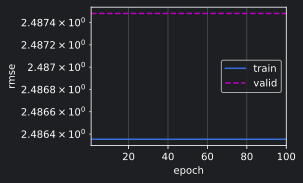

In [7]:
k, num_epochs, lr, weight_decay, batch_size = 5, 100, 5, 0, 64
train_l, valid_l = k_fold(loss,Net(),k, train_features,  torch.log(train_labels), num_epochs, lr,
                          weight_decay, batch_size,testfunc=loss_log_test_func)
print(f'{k}-fold verification: average training log rmse: {float(train_l):f}, '
      f'average verification log rmse: {float(valid_l):f}')

# **Question 4.10.2**
**Is it always a good idea to replace missing values with the mean? Hint: Can you think of a scenario where values are lost in a non-random manner?**

When there are too many missing values and we standardise the data using the mean and variance of the non-missing data, this can result in an excessive number of zeros appearing in the data, which may lead to the loss of information from features with a high number of missing values. We can impute the missing data using neighbouring values or interpolation methods.

折1，训练log rmse0.170086, 验证log rmse0.159162
折2，训练log rmse0.162257, 验证log rmse0.187802
折3，训练log rmse0.163515, 验证log rmse0.167856
折4，训练log rmse0.168632, 验证log rmse0.154878
折5，训练log rmse0.162862, 验证log rmse0.182668
5-fold verification: average verification log rmse: 0.165470, average verification log rmse: 0.170473


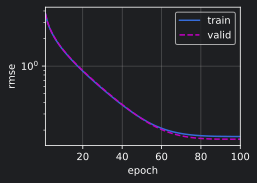

In [8]:
import numpy as np
import torch
from torch import nn
from d2l import torch as d2l
import pandas as pd

all_features2 = pd.concat((train_data.iloc[:, 1:-1], test_data.iloc[:, 1:]))
numeric_features2 = all_features2.select_dtypes(include='number').columns
all_features2[numeric_features2] = all_features2[numeric_features2].apply(
    lambda x: (x - x.mean()) / (x.std() + 1e-7))
# After standardizing the data, we used interpolation to replace the missing values
all_features2[numeric_features2] = all_features2[numeric_features2].interpolate()
all_features2 = pd.get_dummies(all_features2, dummy_na=True)
bool_cols2 = all_features2.select_dtypes(include='bool').columns
all_features2[bool_cols] = all_features2[bool_cols2].astype(int)
n_train = train_data.shape[0]
train_features2 = torch.tensor(all_features2[:n_train].values, dtype=torch.float32)
test_features2 = torch.tensor(all_features2[n_train:].values, dtype=torch.float32)
train_labels2 = torch.tensor(train_data.SalePrice.values.reshape(-1, 1), dtype=torch.float32)
loss = nn.MSELoss()
in_features2 = train_features2.shape[1]

k, num_epochs, lr, weight_decay, batch_size = 5, 100, 5, 0, 64
train_l, valid_l = k_fold(loss,get_net(),k, train_features2, train_labels2, num_epochs, lr,
                          weight_decay, batch_size)
print(f'{k}-fold verification: average verification log rmse: {float(train_l):f}, '
      f'average verification log rmse: {float(valid_l):f}')

# **Question 4.10.3**
**Tune hyperparameters using K-fold cross-validation to improve the Kaggle score.**

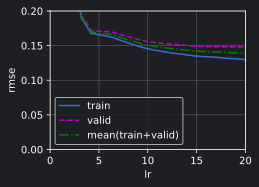

In [2]:
k, num_epochs, weight_decay, batch_size = 5, 100, 0, 64
animator_lr = d2l.Animator(xlabel='lr', ylabel='rmse', xlim=[0,20], ylim=[0.0, 0.2],
                        legend=[ 'train ', 'valid ','mean(train+valid)'])
for lr in np.linspace(0.,20,20):
    train_l, valid_l = k_fold(loss,get_net(),k, train_features, train_labels, num_epochs, lr,
                          weight_decay, batch_size,show=0)
    print(f'lr={float(lr):f}  {k}-fold verification: average training log rmse: {float(train_l):f}, '
            f'average verification log rmse: {float(valid_l):f}')
    animator_lr.add(lr, (train_l, valid_l,0.5*(train_l+valid_l)))

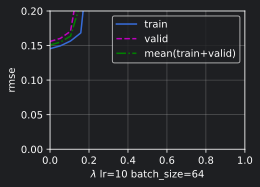

In [3]:
k, num_epochs, lr, batch_size = 5, 100, 10,  64
animator_wd = d2l.Animator(xlabel=f'$\lambda$ lr={lr} batch_size={batch_size}', ylabel='rmse', xlim=[0,1], ylim=[0.0, 0.2],
                        legend=[ 'train ', 'valid ','mean(train+valid)'])
for weight_decay in np.linspace(0.,1.,20):
    train_l, valid_l = k_fold(loss,get_net(),k, train_features, train_labels, num_epochs, lr,
                          weight_decay, batch_size,show=0)

    print(f'weight_decay={float(weight_decay):f}   {k}-fold verification: average training log rmse: {float(train_l):f}, '
            f'average verification log rmse: {float(valid_l):f}')
    animator_wd.add(weight_decay, (train_l, valid_l,0.5*(train_l+valid_l)))

weight_decay_get:0,loss: 0.14192246496677396


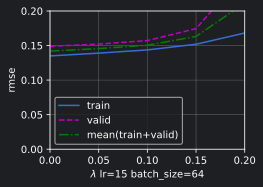

In [4]:
k, num_epochs, lr, batch_size = 5, 100, 15,  64
animator_wd = d2l.Animator(xlabel=f'$\lambda$ lr={lr} batch_size={batch_size}', ylabel='rmse', xlim=[0,0.2], ylim=[0.0, 0.2],
                        legend=[ 'train ', 'valid ','mean(train+valid)'])
findmin=lambda x1,x2,y1,y2: (x1,y1) if y2>=y1 else (x2,y2)
weight_decay_get=0
for weight_decay in np.linspace(0.,0.2,5):
    train_l, valid_l = k_fold(loss,get_net(),k, train_features, train_labels, num_epochs, lr,
                          weight_decay, batch_size,show=0)
    if weight_decay==0:
        l=0.5*(train_l+ valid_l)
    weight_decay_get,l=findmin( weight_decay_get,weight_decay,l,0.5*(train_l+ valid_l))
    print(f'weight_decay={float(weight_decay):f}  {k}-fold verification: average training log rmse: {float(train_l):f}, '
            f'average verification log rmse: {float(valid_l):f}')
    animator_wd.add(weight_decay, (train_l, valid_l,0.5*(train_l+valid_l)))
print(f'weight_decay_get:{weight_decay_get},loss: {l}')

# **Question 4.10.4**
**Improve scores by refining the model (e.g. layers, weight decay and dropout).**

折1，训练log rmse0.139903, 验证log rmse0.144010
折2，训练log rmse0.138071, 验证log rmse0.152008
折3，训练log rmse0.135476, 验证log rmse0.146207
折4，训练log rmse0.141660, 验证log rmse0.139534
折5，训练log rmse0.132871, 验证log rmse0.167960


(0.13759635388851166, 0.14994375705718993)

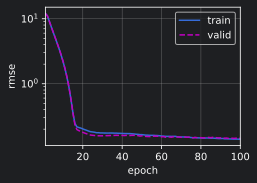

In [5]:
def mynet(num_hiddens,dropout1,dropout2):
    net= nn.Sequential(nn.Linear(in_features,in_features),
                       nn.ReLU(),
                       #nn.Dropout(dropout1),
                       nn.Linear(in_features, int(0.5*in_features)),
                       nn.ReLU(),
                       nn.Dropout(dropout1),
                       nn.Linear(int(0.5*in_features), int(0.5*0.5*in_features)),
                       nn.ReLU(),
                       nn.Dropout(dropout2),
                       nn.Linear(int(0.5*0.5*in_features), num_hiddens),
                       nn.Linear(num_hiddens, 1))
    return net
k, num_hiddens,weight_decay, batch_size,dropout1,dropout2,num_epochs,lr= 5,int(0.5*0.5*0.5*in_features),0, 32,0.2,0.4,100,0.0001
k_fold(loss,mynet(int(num_hiddens),dropout1,dropout2),k, train_features,  train_labels, num_epochs, lr,
                          weight_decay, batch_size,show=1)

In [6]:
def train_and_pred(net,loss,train_features, test_features, train_labels, test_data,
                   num_epochs, lr, weight_decay, batch_size,name='submission.csv',f=lambda x: x.detach().numpy()):
    #net = get_net()
    train_ls, _ = train(net,loss,train_features, train_labels, None, None,
                        num_epochs, lr, weight_decay, batch_size)
    d2l.plot(np.arange(1, num_epochs + 1), [train_ls], xlabel='epoch',
             ylabel='log rmse', xlim=[1, num_epochs], yscale='log')
    print(f'training log rmse：{float(train_ls[-1]):f}')
    net.eval()
    preds = f(net(test_features))
    test_data['SalePrice'] = pd.Series(preds.reshape(1, -1)[0])
    submission = pd.concat([test_data['Id'], test_data['SalePrice']], axis=1)
    submission.to_csv(name, index=False)

training log rmse：0.133673


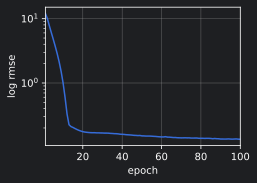

In [7]:
k, num_hiddens,weight_decay, batch_size,dropout1,dropout2,num_epochs,lr= 5,int(0.5*0.5*0.5*in_features),0, 32,0.2,0.4,100,0.0001

train_and_pred(mynet(int(num_hiddens),dropout1,dropout2),loss,train_features, test_features, train_labels, test_data,
                   num_epochs, lr, weight_decay, batch_size,name='../../data/ch04-4-10-5-submission.csv')

# **Question 4.10.5**
**What would happen if we did not standardise continuous numerical features as we have done in this section?**<br><br>
This can result in the model paying disproportionate attention to features with large values compared to those with small values during computation, thereby failing to treat each feature fairly; it may also lead to numerical instability, making training impossible.

折1，训练log rmse0.170691, 验证log rmse0.157204
折2，训练log rmse0.162168, 验证log rmse0.190059
折3，训练log rmse0.164249, 验证log rmse0.168346
折4，训练log rmse0.168424, 验证log rmse0.155075
折5，训练log rmse0.163089, 验证log rmse0.182652
5-fold: average training log rmse: 0.165724, average verification log rmse: 0.170667


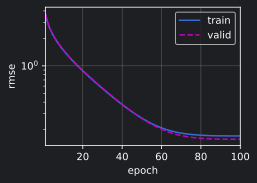

In [10]:
all_features3 = pd.concat((train_data.iloc[:, 1:-1], test_data.iloc[:, 1:]))
numeric_features3 = all_features3.select_dtypes(include='number').columns
all_features3[numeric_features3] = all_features3[numeric_features3].apply(
    lambda x: (x - x.mean()) / (x.std() + 1e-7))

all_features3[numeric_features3] = all_features3[numeric_features3].fillna(all_features3[numeric_features3].mean())
all_features3 = pd.get_dummies(all_features3, dummy_na=True)
n_train = train_data.shape[0]
bool_cols3 = all_features3.select_dtypes(include='bool').columns
all_features3[bool_cols3] = all_features3[bool_cols3].astype(int)
train_features3 = torch.tensor(all_features3[:n_train].values, dtype=torch.float32)
test_features3 = torch.tensor(all_features3[n_train:].values, dtype=torch.float32)
train_labels3 = torch.tensor(train_data.SalePrice.values.reshape(-1, 1), dtype=torch.float32)
loss = nn.MSELoss()
in_features3 = train_features3.shape[1]
def get_net():
    net= nn.Sequential(nn.Linear(in_features3,1))
    return net
k, num_epochs, lr, weight_decay, batch_size = 5, 100, 5, 0, 64
train_l, valid_l = k_fold(loss,get_net(),k, train_features3, train_labels3, num_epochs, lr,
                          weight_decay, batch_size)
print(f'{k}-fold: average training log rmse: {float(train_l):f}, '
      f'average verification log rmse: {float(valid_l):f}')